# Dynamical categories: data vs model (turbulence_ggd_mass_final, seed 904)
Same rule-based labels for the 10000 training signals and the 10000 generated samples (rule in `categories_seed904.json`). Categories are clean only at the extremes; counts are a coarse indicator. Light: loads two 10 MB tensors, no model run.

In [6]:
import json, os, sys
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline

# repo root = first folder (cwd or a parent) containing codes/ and turbulence/: works locally and on JZ
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'codes').is_dir() and (p / 'turbulence').is_dir())
for p in (ROOT, ROOT / 'codes', ROOT / 'data'):
    sys.path.insert(0, str(p))
local_data = ROOT / 'data/data_files/turbulence_1d_period.pt'
if local_data.exists():  # otherwise data_loader's default (JZ Lustre path) is used
    os.environ.setdefault('TURBULENCE_1D_DATA_PATH', str(local_data))
print('ROOT', ROOT)
from codes.utils import normalize, split_periodize_reshape
from codes.ortho_wavelet.ReadyToUseWavelets import DefineWavelet
from data.data_loader import load_turbulence_1d

HERE = ROOT / 'turbulence/sample_categories'
TAG = 'bicw_allmass_scat4_seed904'   # or 'mass_final_seed904' for the other model
info = json.load(open(HERE / f'categories_{TAG}.json'))
labels = np.load(HERE / f'labels_{TAG}.npz')

ROOT /lustre/fswork/projects/rech/wbg/ukv59en/MGD-for-Maximum-Entropy-Generation


## Load signals
Data rebuilt exactly as in `run_SDE.py` (`Data[:n1]`, 512 -> one Db step -> 256, normalize).

In [7]:
raw = load_turbulence_1d()
dt = split_periodize_reshape(raw, 512)
W = DefineWavelet('Db', m=3, device='cpu')
for _ in range(int(np.log2(dt.shape[-1] / 256))):
    dt = W.decompose(dt)[1]
data = normalize(dt[:10000]).numpy()[:, 0]
model = torch.load(ROOT / info['model_samples'], map_location='cpu').numpy()[:, 0]
print(data.shape, model.shape)

(10000, 256) (10000, 256)


## Counts per category

       quiet  data  4960  model  5045  model/data 1.02
     rippled  data  1330  model  1421  model/data 1.07
        step  data  1261  model  1139  model/data 0.90
       spike  data  1482  model  1525  model/data 1.03
      packet  data   383  model   343  model/data 0.90
 multi-burst  data   584  model   527  model/data 0.90


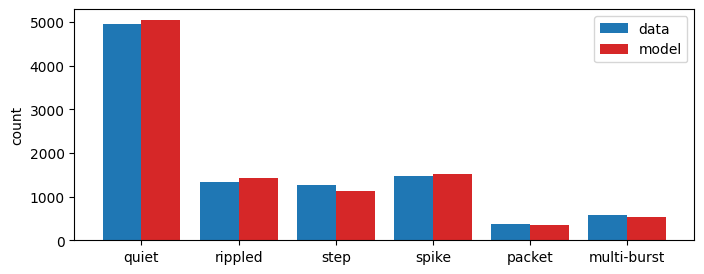

In [8]:
cats = info['categories']
nd = [int((labels['data'] == c).sum()) for c in cats]
nm = [int((labels['model'] == c).sum()) for c in cats]
x = np.arange(len(cats))
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(x - 0.2, nd, 0.4, label='data', color='C0')
ax.bar(x + 0.2, nm, 0.4, label='model', color='C3')
ax.set_xticks(x, cats); ax.set_ylabel('count'); ax.legend()
for c, a, b in zip(cats, nd, nm):
    print(f'{c:>12}  data {a:5d}  model {b:5d}  model/data {b / a:.2f}')

## Examples per category
`which="clearest"`: strongest members (archetype). `which="random"`: random members (how mixed the category is). Titles = position in the dataset / samples tensor.

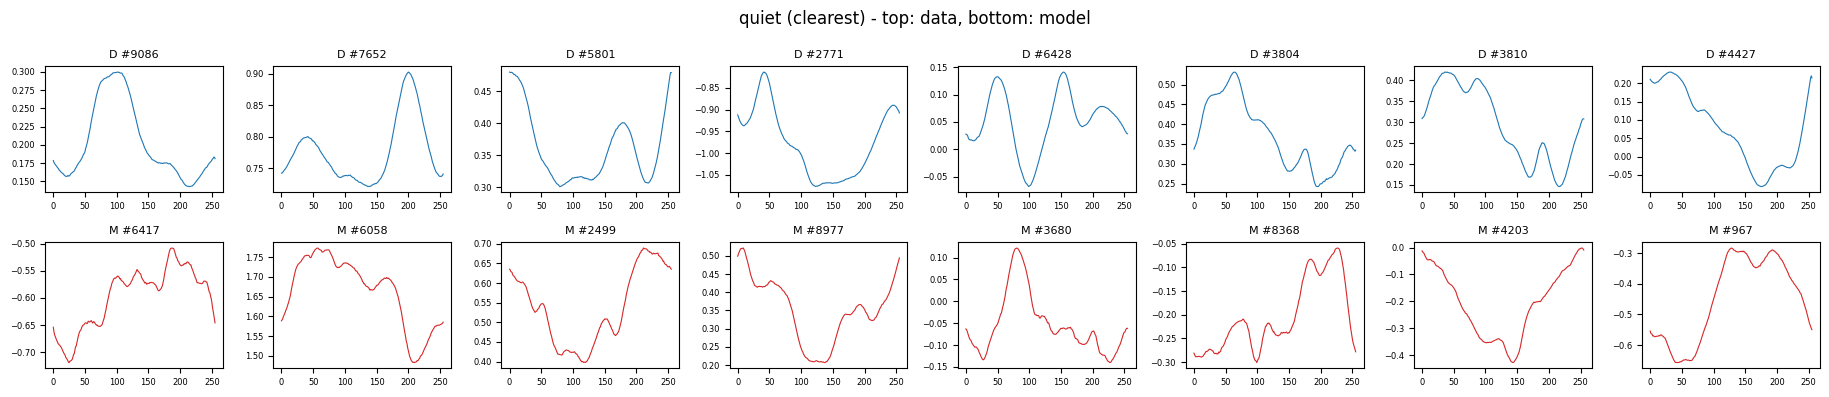

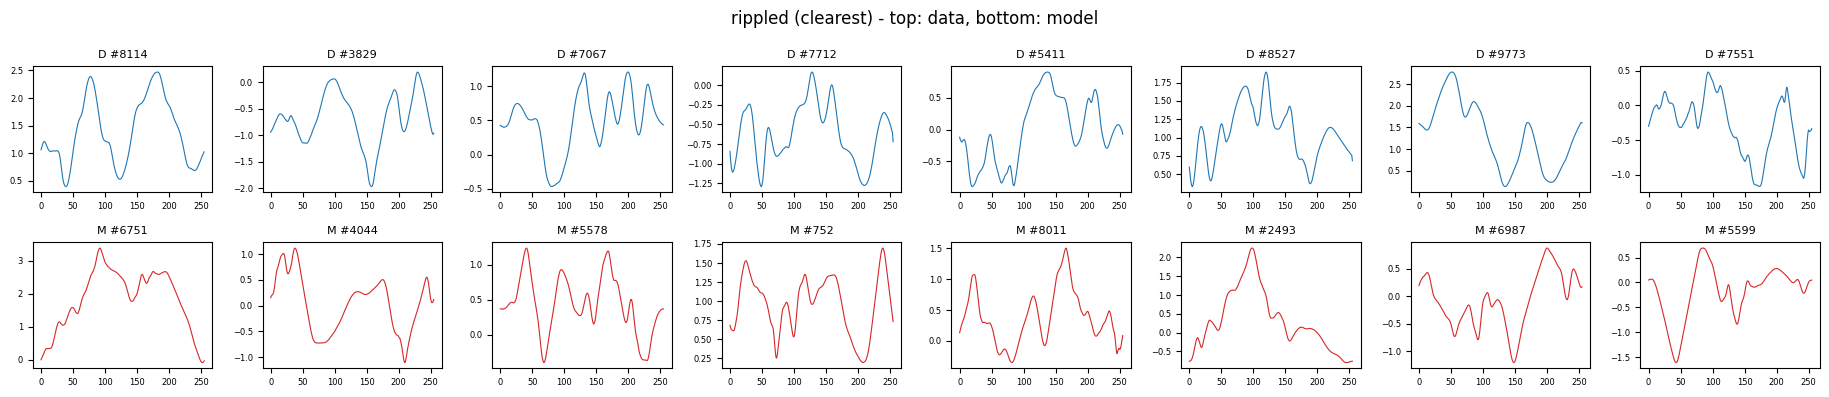

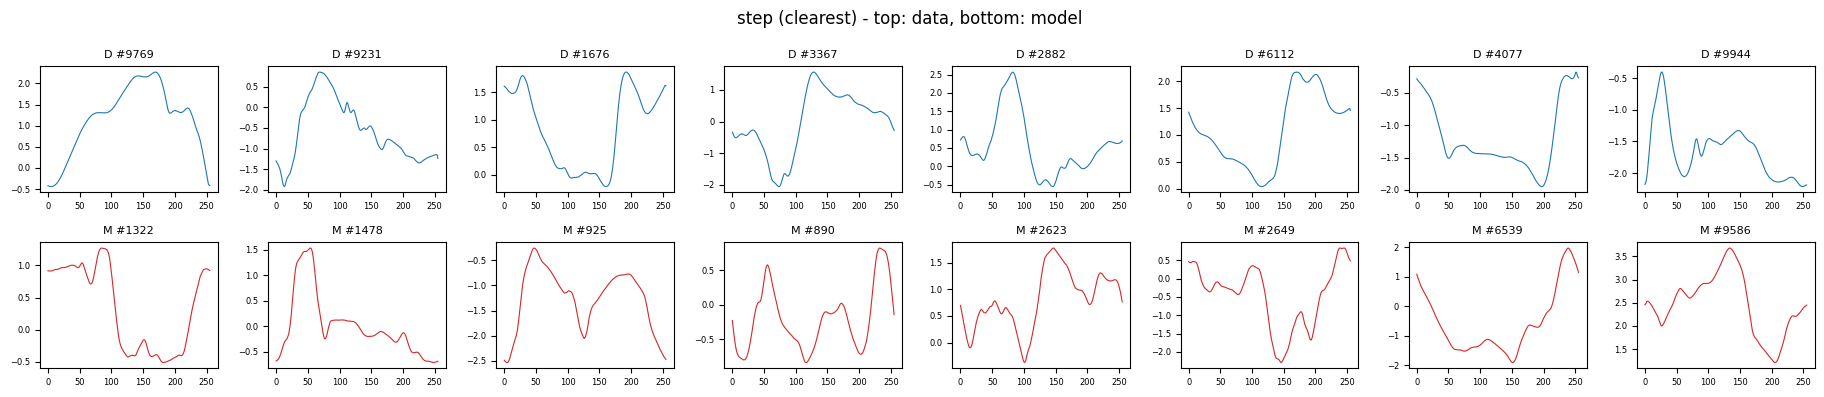

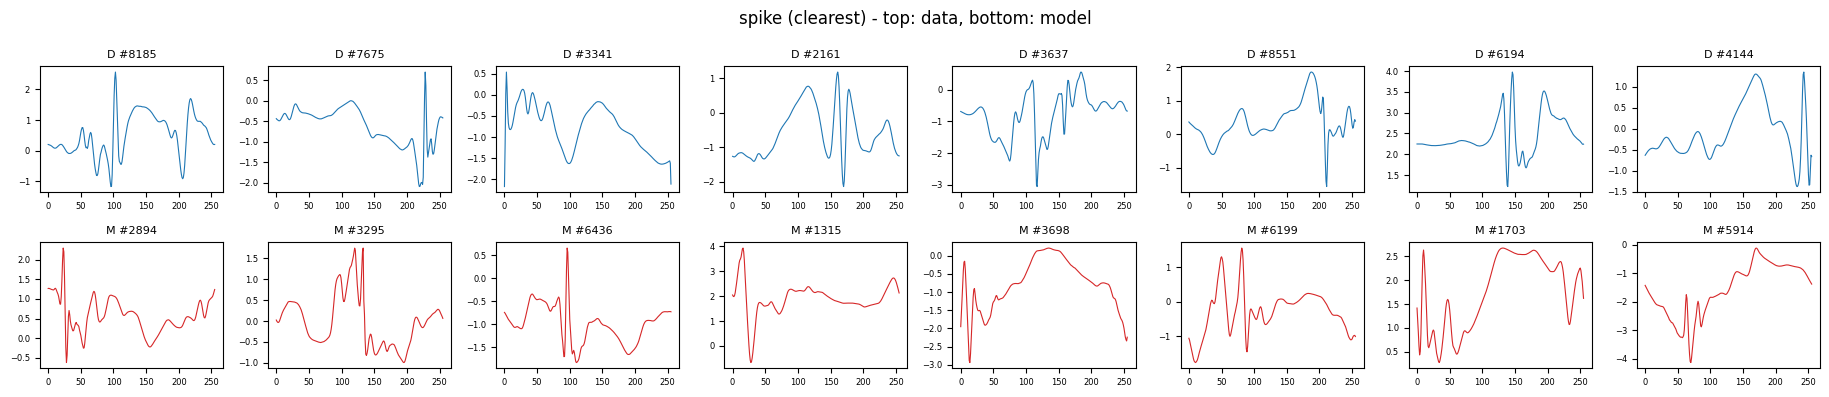

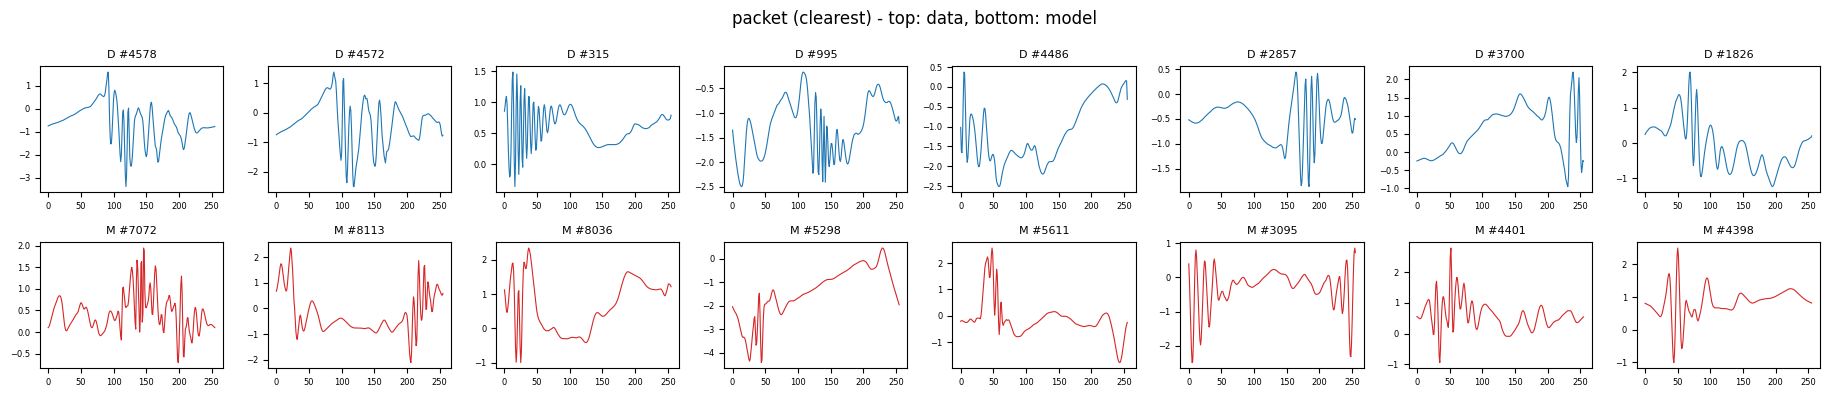

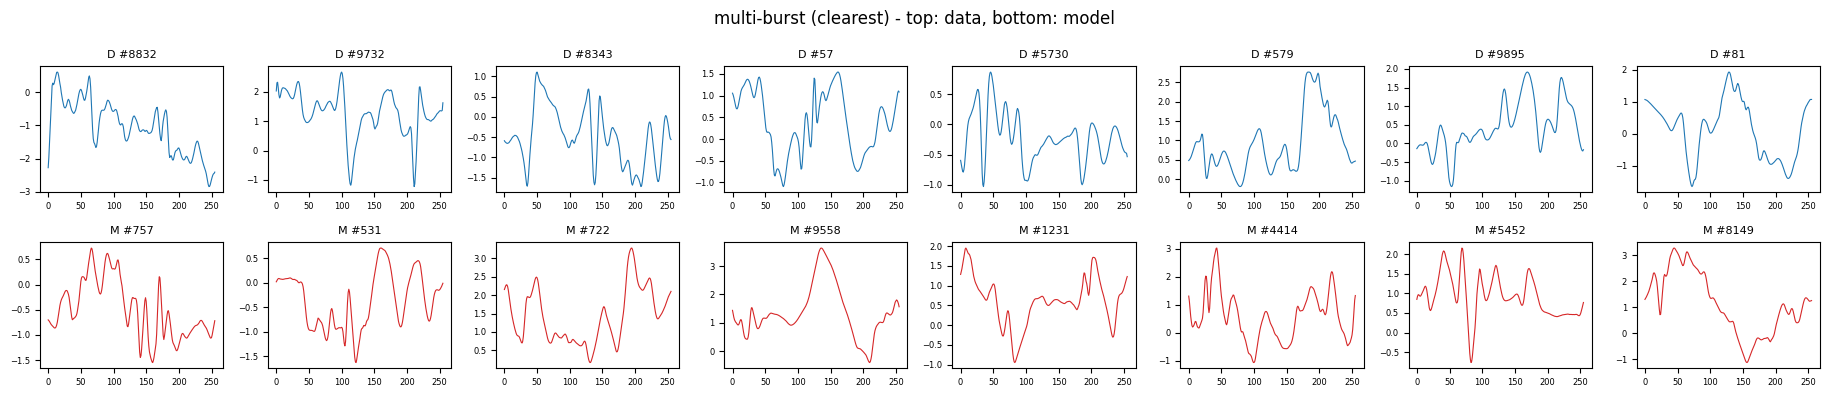

In [9]:
def show(cat, which='clearest', n=8):
    fig, axs = plt.subplots(2, n, figsize=(2.3 * n, 4))
    for r, (key, X, col) in enumerate((('data', data, 'C0'), ('model', model, 'C3'))):
        for ax, i in zip(axs[r], info[which][cat][key][:n]):
            ax.plot(X[i], lw=0.8, color=col)
            ax.set_title(f'{key[0].upper()} #{i}', fontsize=8)
            ax.tick_params(labelsize=6)
    fig.suptitle(f'{cat} ({which}) - top: data, bottom: model')
    fig.tight_layout()

for c in cats:
    show(c, 'clearest')

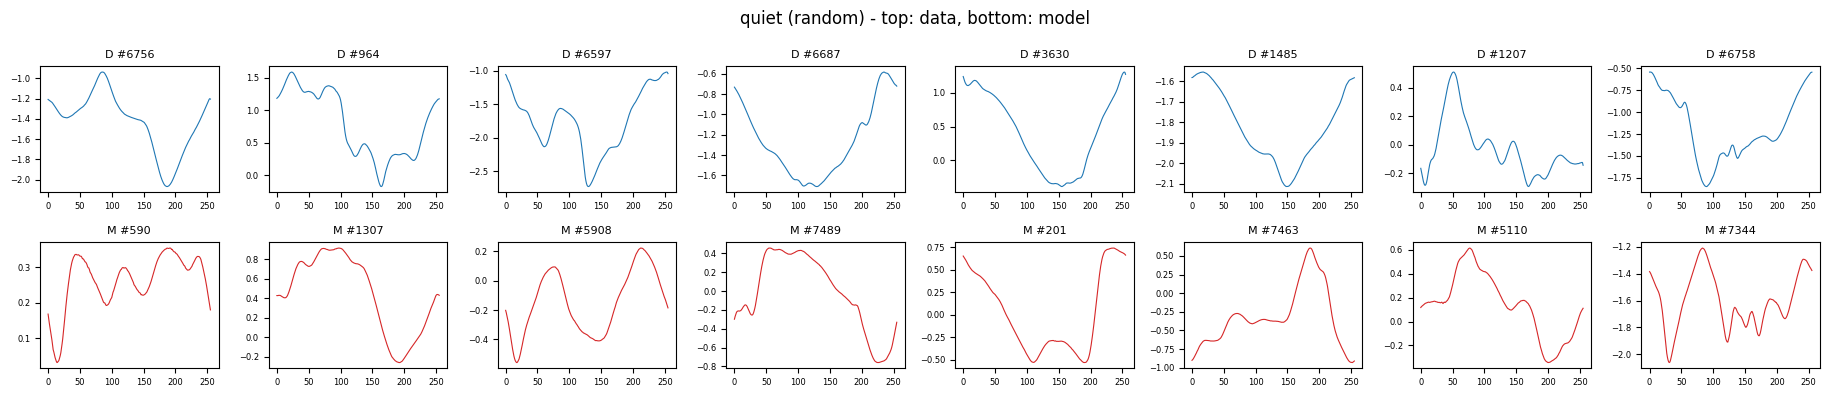

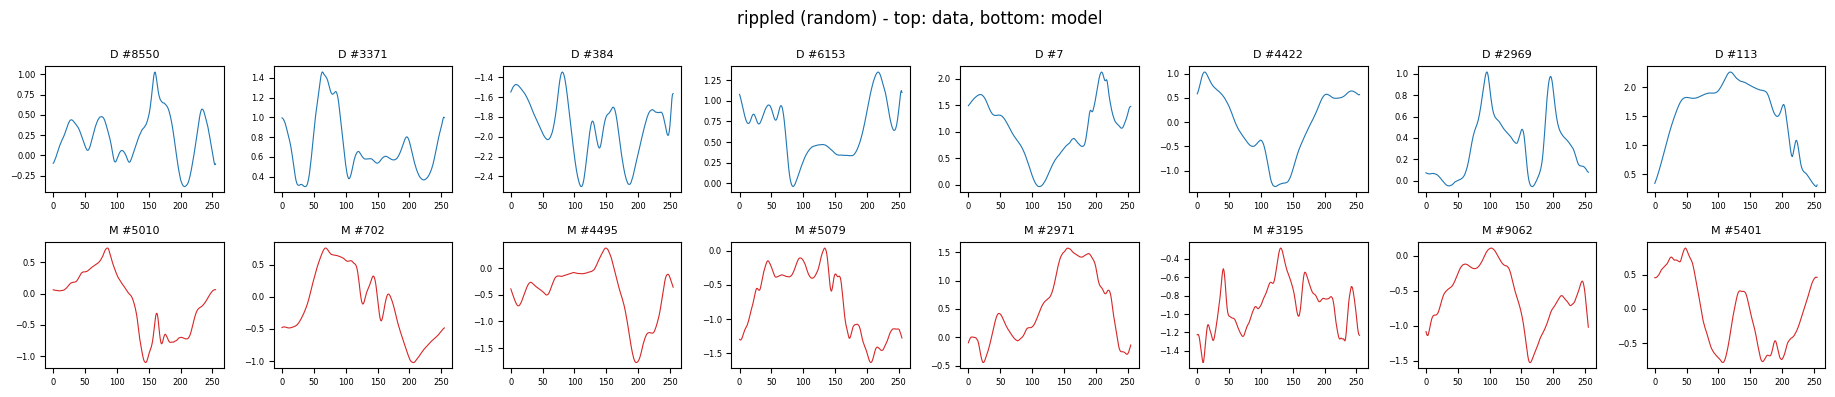

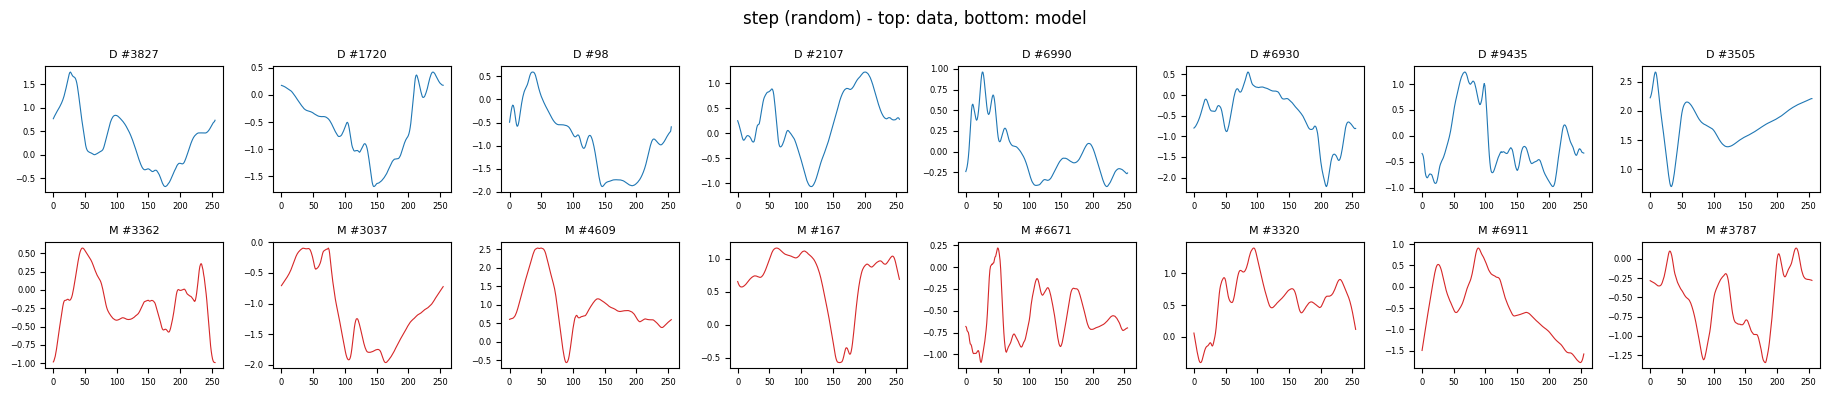

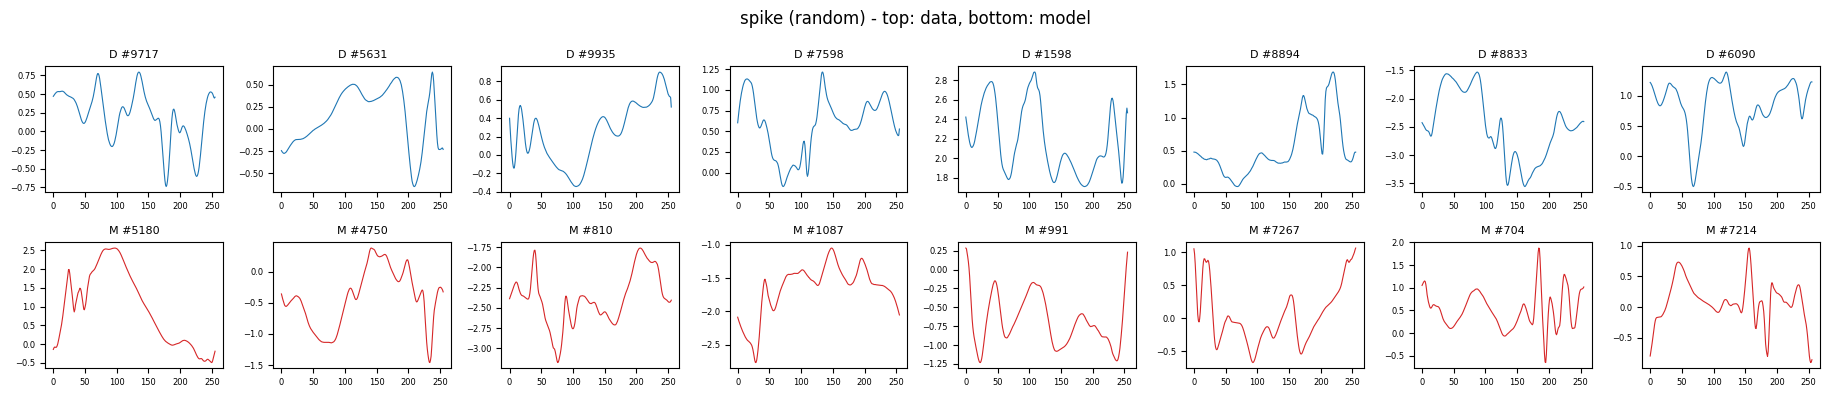

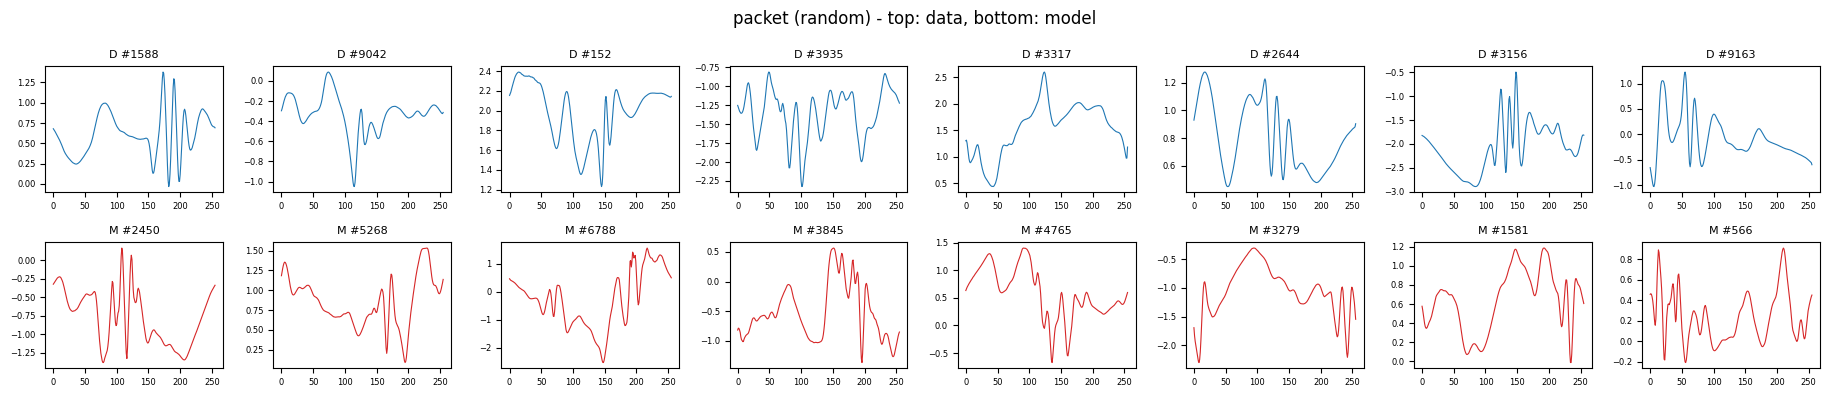

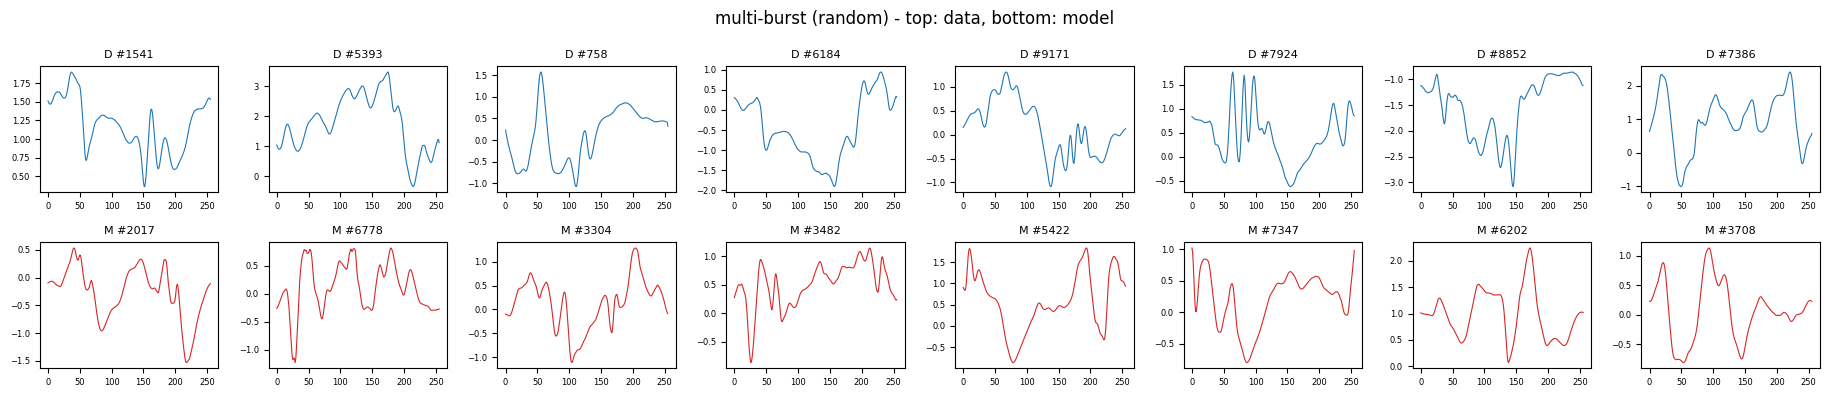

In [10]:
for c in cats:
    show(c, 'random')